In [2]:
"""
AE-SepSpace: usulan pengembangan dari replikasi Jurnal 2 (SepSpace) dan Jurnal 3 (AECCN).

Ide inti
--------
1. Dari AECCN [1]  : Autoencoder (AE) merekonstruksi bagian aliran yang kosong (zero-padding).
   Perbaikan        : AE dilatih TANPA label dan lintas kelas (class-agnostic), karena pada
                      open-set kelas aliran uji tidak diketahui saat inferensi. Rekonstruksi
                      hanya mengisi posisi padding; paket asli tidak diubah.
2. Dari SepSpace [4]: encoder + supervised contrastive learning + penolakan prototipe-radius.
   Perbaikan        : radius per kelas dikalibrasi dengan split conformal prediction
                      (bukan persentil-95 tetap) dan dapat diperbarui adaptif saat operasi.

Alur: aliran (arah, panjang paket) -> AE pengisi padding -> encoder CNN1D + SupCon
      -> jarak cosine ke prototipe -> terima (kelas k) atau tolak (tak dikenal).

PENTING: bagian __main__ memakai data SINTETIS hanya untuk uji alur (sanity check).
Angka yang keluar bukan hasil benchmark. Untuk eksperimen sebenarnya, ganti
`make_synthetic` dengan loader PCAP asli (lihat fungsi `load_flows_from_arrays`).
"""
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

L = 64
MTU = 1500.0


# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
def make_synthetic(n_classes=5, n_per_class=400, seed=0, short_frac=0.5):
    """Data sintetis berstruktur: tiap kelas punya pola panjang/arah khas.
    Panjang aliran bervariasi (sebagian pendek) agar zero-padding berdampak."""
    rng = np.random.default_rng(seed)
    protos = []
    for _ in range(n_classes):
        base = rng.uniform(0.1, 1.0, size=8)
        dirs = rng.choice([-1.0, 1.0], size=8)
        protos.append((base, dirs))
    X, M, y = [], [], []
    for c, (base, dirs) in enumerate(protos):
        for _ in range(n_per_class):
            n = rng.integers(4, 12) if rng.random() < short_frac else rng.integers(24, L + 1)
            idx = np.arange(n) % 8
            v = base[idx] * (1 + 0.15 * rng.standard_normal(n))
            v = np.clip(v, 0.02, 1.0) * dirs[idx]
            x = np.zeros(L, dtype=np.float32)
            m = np.zeros(L, dtype=np.float32)
            x[:n], m[:n] = v, 1.0
            X.append(x); M.append(m); y.append(c)
    return np.array(X), np.array(M), np.array(y)


def load_flows_from_arrays(lengths, directions, max_len=L):
    """Hook untuk data asli. lengths/directions: list array per aliran (hasil Scapy).
    Mengembalikan X (nilai bertanda, dinormalisasi MTU) dan mask M."""
    X = np.zeros((len(lengths), max_len), dtype=np.float32)
    M = np.zeros_like(X)
    for i, (ln, dr) in enumerate(zip(lengths, directions)):
        n = min(len(ln), max_len)
        X[i, :n] = np.clip(np.asarray(ln[:n], float), 0, MTU) / MTU * np.where(np.asarray(dr[:n]) > 0, 1, -1)
        M[i, :n] = 1.0
    return X, M


def truncate(X, M, k):
    """Simulasi aliran pendek: hanya k paket pertama yang teramati."""
    X2, M2 = X.copy(), M.copy()
    X2[:, k:], M2[:, k:] = 0.0, 0.0
    return X2, M2


# ----------------------------------------------------------------------------
# 2. Autoencoder pengisi padding (adaptasi AECCN, tanpa label)
# ----------------------------------------------------------------------------
class PadAE(nn.Module):
    def __init__(self, h=64, z=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(2 * L, h), nn.ReLU(), nn.Linear(h, z), nn.ReLU())
        self.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, L), nn.Tanh())

    def forward(self, x, m):
        return self.dec(self.enc(torch.cat([x * m, m], 1)))

    @torch.no_grad()
    def fill(self, x, m):
        """Isi hanya posisi padding; paket asli dipertahankan."""
        r = self.forward(x, m)
        return x * m + r * (1 - m)


def train_ae(ae, X, M, epochs=30, lr=2e-3, bs=128):
    """Denoising: aliran dipotong acak lebih pendek, AE belajar memulihkan bagian yang hilang.
    Loss dihitung hanya pada posisi yang sebenarnya ada paketnya di aliran asli."""
    X, M = torch.tensor(X), torch.tensor(M)
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]
            x, m = X[b], M[b]
            n = m.sum(1)
            keep = (torch.rand(len(b)) * (n - 3) + 3).long()
            pos = torch.arange(L).unsqueeze(0)
            m_in = (pos < keep.unsqueeze(1)).float() * m
            loss = (((ae(x, m_in) - x) ** 2) * m).sum() / m.sum()
            opt.zero_grad(); loss.backward(); opt.step()
    return ae


# ----------------------------------------------------------------------------
# 3. Encoder + SupCon (adaptasi SepSpace)
# ----------------------------------------------------------------------------
class Encoder(nn.Module):
    def __init__(self, n_cls, d=64, dp=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(2, 32, 3, padding=1), nn.ReLU(),
            nn.Conv1d(32, d, 3, padding=1), nn.ReLU())
        self.cls = nn.Linear(d, n_cls)
        self.proj = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, dp))

    def embed(self, x, m):
        h = self.conv(torch.stack([x, m], 1))
        w = m.unsqueeze(1)
        return (h * w).sum(2) / w.sum(2).clamp(min=1)

    def forward(self, x, m):
        h = self.embed(x, m)
        return self.cls(h), F.normalize(self.proj(h), dim=1)


def supcon(z, y, T=0.07):
    sim = z @ z.t() / T
    eye = torch.eye(len(z), device=z.device).bool()
    sim = sim.masked_fill(eye, -1e9)
    pos = (y.unsqueeze(0) == y.unsqueeze(1)) & ~eye
    logp = sim - torch.logsumexp(sim, 1, keepdim=True)
    cnt = pos.sum(1)
    ok = cnt > 0
    return -((logp * pos).sum(1)[ok] / cnt[ok]).mean()


def train_encoder(net, X, M, y, ep1=15, ep2=15, lr=2e-3, bs=128, lam=0.5):
    X, M, y = torch.tensor(X), torch.tensor(M), torch.tensor(y)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(ep1 + ep2):
        stage2 = ep >= ep1
        if stage2 and ep == ep1:
            for p in net.cls.parameters():
                p.requires_grad = False
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]
            lg, z = net(X[b], M[b])
            loss = F.cross_entropy(lg, y[b])
            if stage2:
                loss = loss + lam * supcon(z, y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return net


# ----------------------------------------------------------------------------
# 4. Prototipe + radius penolakan (persentil-95 vs conformal adaptif)
# ----------------------------------------------------------------------------
@torch.no_grad()
def embeddings(net, X, M):
    net.eval()
    return F.normalize(net.embed(torch.tensor(X), torch.tensor(M)), dim=1).numpy()


class OpenSetHead:
    def __init__(self, n_cls):
        self.K = n_cls
        self.protos = None
        self.radius = None

    def fit_prototypes(self, E, y):
        P = np.stack([E[y == k].mean(0) for k in range(self.K)])
        self.protos = P / np.linalg.norm(P, axis=1, keepdims=True)

    def dist(self, E):
        return 1.0 - E @ self.protos.T

    def calibrate(self, E, y, mode="conformal", alpha=0.05):
        """mode='percentile': radius = persentil ke-95 (gaya SepSpace asli).
        mode='conformal'   : kuantil terkoreksi ceil((n+1)(1-alpha))/n pada skor kelas benar,
                             sehingga FRR pada kelas dikenal ~ alpha (asumsi exchangeable)."""
        D = self.dist(E)
        self.radius = np.zeros(self.K)
        for k in range(self.K):
            d = D[y == k, k]
            if mode == "percentile":
                self.radius[k] = np.percentile(d, 95)
            else:
                n = len(d)
                q = min(1.0, math.ceil((n + 1) * (1 - alpha)) / n)
                self.radius[k] = np.quantile(d, q, method="higher")

    def adapt(self, E_new, ema=0.02):
        """Pembaruan radius saat operasi dari sampel yang diterima secara meyakinkan
        (jarak < 0.8 * radius). Hanya menggeser radius perlahan (EMA)."""
        D = self.dist(E_new)
        k = D.argmin(1)
        d = D[np.arange(len(k)), k]
        for c in np.unique(k):
            sel = (k == c) & (d < 0.8 * self.radius[c])
            if sel.any():
                target = np.quantile(d[sel], 0.95) / 0.8
                self.radius[c] = (1 - ema) * self.radius[c] + ema * target

    def predict(self, E):
        D = self.dist(E)
        k = D.argmin(1)
        d = D[np.arange(len(k)), k]
        reject = d > self.radius[k]
        return np.where(reject, -1, k), d


# ----------------------------------------------------------------------------
# 5. Metrik
# ----------------------------------------------------------------------------
def oscr(d_known, correct, d_unk):
    th = np.sort(np.concatenate([d_known, d_unk]))
    ccr = np.array([np.mean((d_known <= t) & correct) for t in th])
    fpr = np.array([np.mean(d_unk <= t) for t in th])
    trap = getattr(np, 'trapezoid', None) or np.trapz   # NumPy 2.x vs 1.x
    return float(trap(ccr, fpr))


def evaluate(head, Ek, yk, Eu):
    pk, dk = head.predict(Ek)
    _, du = head.predict(Eu)
    D = head.dist(Ek)
    closed_acc = float(np.mean(D.argmin(1) == yk))
    correct = D.argmin(1) == yk
    auroc = float(roc_auc_score(np.r_[np.zeros(len(dk)), np.ones(len(du))], np.r_[dk, du]))
    thr95 = np.percentile(dk, 95)
    return {
        "Acc_closed": closed_acc,
        "AUROC": auroc,
        "OSCR": oscr(dk, correct, du),
        "FPR95": float(np.mean(du <= thr95)),
        "FRR_known": float(np.mean(pk == -1)),
        "DR_novel": float(np.mean(head.predict(Eu)[0] == -1)),
    }


# ----------------------------------------------------------------------------
# 6. Eksperimen: ablasi AE-fill dan radius conformal
# ----------------------------------------------------------------------------
def run(seed=0, novel=4, test_len=None, use_ae=True, radius_mode="conformal", return_details=False):
    torch.manual_seed(seed); np.random.seed(seed)
    X, M, y = make_synthetic(seed=seed)
    known = y != novel
    Xk, Mk, yk = X[known], M[known], y[known]
    Xu, Mu = X[~known], M[~known]
    n = len(Xk); idx = np.random.permutation(n)
    tr, ca, te = idx[:int(.6 * n)], idx[int(.6 * n):int(.8 * n)], idx[int(.8 * n):]
    K = len(np.unique(yk))

    ae = None
    if use_ae:
        ae = train_ae(PadAE(), Xk[tr], Mk[tr])

    def prep(Xa, Ma):
        if test_len is not None:
            Xa, Ma = truncate(Xa, Ma, test_len)
        if ae is not None:
            ae.eval()
            Xa = ae.fill(torch.tensor(Xa), torch.tensor(Ma)).numpy()
        return Xa.astype(np.float32), Ma

    net = train_encoder(Encoder(K), *prep(Xk[tr], Mk[tr]), yk[tr])
    head = OpenSetHead(K)
    head.fit_prototypes(embeddings(net, *prep(Xk[tr], Mk[tr])), yk[tr])
    head.calibrate(embeddings(net, *prep(Xk[ca], Mk[ca])), yk[ca], mode=radius_mode)
    Ek, Eu = embeddings(net, *prep(Xk[te], Mk[te])), embeddings(net, *prep(Xu, Mu))
    res = evaluate(head, Ek, yk[te], Eu)
    if not return_details:
        return res
    pk, dk = head.predict(Ek)
    pu, du = head.predict(Eu)
    return res, dict(y_known=yk[te], pred_known=pk, d_known=dk,
                     pred_unk=pu, d_unk=du, radius=head.radius.copy(), n_cls=K)


# ----------------------------------------------------------------------------
# 7. Visualisasi hasil (matriks evaluasi)
# ----------------------------------------------------------------------------
def _plt():
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def plot_confusion_open_set(det, path, title=""):
    """Confusion matrix open-set: baris = kelas sebenarnya (+ 'Novel'),
    kolom = prediksi (kelas dikenal + 'Ditolak'). Dinormalisasi per baris."""
    plt = _plt()
    K = det["n_cls"]
    M = np.zeros((K + 1, K + 1))
    for t, p in zip(det["y_known"], det["pred_known"]):
        M[t, K if p == -1 else p] += 1
    for p in det["pred_unk"]:
        M[K, K if p == -1 else p] += 1
    Mn = M / M.sum(1, keepdims=True).clip(min=1)
    labels = [f"K{i}" for i in range(K)]
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    im = ax.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels + ["Ditolak"])
    ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels + ["Novel"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Kelas sebenarnya"); ax.set_title(title)
    for i in range(K + 1):
        for j in range(K + 1):
            ax.text(j, i, f"{Mn[i, j]:.2f}\n({int(M[i, j])})", ha="center", va="center",
                    fontsize=8, color="white" if Mn[i, j] > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046); fig.tight_layout()
    fig.savefig(path, dpi=160); plt.close(fig)


def plot_roc(dets, path):
    """Kurva ROC open-set (skor = jarak ke prototipe terdekat; positif = trafik baru)."""
    from sklearn.metrics import roc_curve
    plt = _plt()
    fig, ax = plt.subplots(figsize=(5.2, 5))
    for name, det in dets.items():
        yt = np.r_[np.zeros(len(det["d_known"])), np.ones(len(det["d_unk"]))]
        sc = np.r_[det["d_known"], det["d_unk"]]
        fpr, tpr, _ = roc_curve(yt, sc)
        ax.plot(fpr, tpr, label=f"{name} (AUROC={roc_auc_score(yt, sc):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("False positive rate (kelas dikenal salah ditolak)")
    ax.set_ylabel("True positive rate (trafik baru terdeteksi)")
    ax.set_title("Kurva ROC open-set"); ax.legend(fontsize=7, loc="lower right")
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def plot_distance_hist(det, path, title=""):
    """Sebaran jarak ke prototipe: kelas dikenal vs trafik baru, dengan radius penolakan."""
    plt = _plt()
    fig, ax = plt.subplots(figsize=(6.4, 4))
    bins = np.linspace(0, max(det["d_known"].max(), det["d_unk"].max()), 40)
    ax.hist(det["d_known"], bins=bins, alpha=0.6, label="Kelas dikenal", color="tab:blue")
    ax.hist(det["d_unk"], bins=bins, alpha=0.6, label="Trafik baru (novel)", color="tab:red")
    ax.axvline(np.mean(det["radius"]), color="k", ls="--", label="Rerata radius penolakan")
    ax.set_xlabel("Jarak cosine ke prototipe terdekat"); ax.set_ylabel("Jumlah sampel")
    ax.set_title(title); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def plot_metric_matrix(table, path, title=""):
    """Heatmap matriks evaluasi: baris = varian metode, kolom = metrik (rerata antar seed).
    table: {nama_varian: {metrik: (rerata, std)}}"""
    plt = _plt()
    rows = list(table); cols = list(next(iter(table.values())))
    A = np.array([[table[r][c][0] for c in cols] for r in rows])
    S = np.array([[table[r][c][1] for c in cols] for r in rows])
    fig, ax = plt.subplots(figsize=(1.35 * len(cols) + 2.5, 0.7 * len(rows) + 1.8))
    im = ax.imshow(A, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha="right")
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=8)
    for i in range(len(rows)):
        for j in range(len(cols)):
            ax.text(j, i, f"{A[i, j]:.3f}\n±{S[i, j]:.3f}", ha="center", va="center",
                    fontsize=7, color="white" if A[i, j] > 0.6 else "black")
    ax.set_title(title, fontsize=10); fig.colorbar(im, ax=ax, fraction=0.03)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def plot_metric_bars(table_by_scenario, path, metrics=("AUROC", "FRR_known", "DR_novel")):
    """Diagram batang pembanding varian untuk tiap skenario, dengan error bar (std antar seed)."""
    plt = _plt()
    scen = list(table_by_scenario)
    variants = list(table_by_scenario[scen[0]])
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.6 * len(metrics), 4), sharey=True)
    w = 0.8 / len(variants); x = np.arange(len(scen))
    for ax, met in zip(np.atleast_1d(axes), metrics):
        for i, v in enumerate(variants):
            m = [table_by_scenario[s][v][met][0] for s in scen]
            e = [table_by_scenario[s][v][met][1] for s in scen]
            ax.bar(x + i * w, m, w, yerr=e, capsize=3, label=v)
        ax.set_xticks(x + w * (len(variants) - 1) / 2); ax.set_xticklabels(scen, fontsize=8)
        ax.set_title(met); ax.set_ylim(0, 1.05)
    h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=len(variants), fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0.08, 1, 1)); fig.savefig(path, dpi=160); plt.close(fig)


if __name__ == "__main__":
    import os
    OUT = "hasil_visualisasi"; os.makedirs(OUT, exist_ok=True)
    SEEDS = range(3)
    configs = {
        "Baseline (zero-pad + persentil-95)": dict(use_ae=False, radius_mode="percentile"),
        "+ AE pengisi padding":               dict(use_ae=True,  radius_mode="percentile"),
        "AE-SepSpace (AE + conformal)":       dict(use_ae=True,  radius_mode="conformal"),
    }
    scenarios = {"Aliran penuh": None, "8 paket pertama": 8}

    by_scen, details = {}, {}
    for sname, tl in scenarios.items():
        print(f"\n=== {sname} (data SINTETIS, {len(SEEDS)} seed) ===")
        by_scen[sname] = {}
        for name, cfg in configs.items():
            rs = []
            for s in SEEDS:
                r, d = run(seed=s, test_len=tl, return_details=True, **cfg)
                rs.append(r)
                if s == 0:
                    details[(sname, name)] = d          # simpan seed 0 untuk plot detail
            agg = {k: (np.mean([r[k] for r in rs]), np.std([r[k] for r in rs])) for k in rs[0]}
            by_scen[sname][name] = agg
            print(f"{name:38s} " + "  ".join(f"{k}={m:.3f}±{sd:.3f}" for k, (m, sd) in agg.items()))
        plot_metric_matrix(by_scen[sname], f"{OUT}/matriks_metrik_{'penuh' if tl is None else 'pendek'}.png",
                           title=f"Matriks evaluasi - {sname} (sintetis, rerata ± std {len(SEEDS)} seed)")

    plot_metric_bars(by_scen, f"{OUT}/perbandingan_varian.png")
    for sname in scenarios:
        tag = "penuh" if scenarios[sname] is None else "pendek"
        plot_roc({n: details[(sname, n)] for n in configs}, f"{OUT}/roc_{tag}.png")
    full = "AE-SepSpace (AE + conformal)"
    for sname in scenarios:
        tag = "penuh" if scenarios[sname] is None else "pendek"
        plot_confusion_open_set(details[(sname, full)], f"{OUT}/confusion_{tag}.png",
                                title=f"Confusion matrix open-set - AE-SepSpace ({sname})")
        plot_distance_hist(details[(sname, full)], f"{OUT}/distribusi_jarak_{tag}.png",
                           title=f"Sebaran jarak - AE-SepSpace ({sname})")
    print(f"\nVisualisasi disimpan di folder: {OUT}/")


=== Aliran penuh (data SINTETIS, 3 seed) ===
Baseline (zero-pad + persentil-95)     Acc_closed=0.994±0.007  AUROC=0.845±0.013  OSCR=0.845±0.013  FPR95=0.945±0.039  FRR_known=0.058±0.014  DR_novel=0.362±0.149
+ AE pengisi padding                   Acc_closed=0.995±0.005  AUROC=0.900±0.020  OSCR=0.900±0.020  FPR95=0.695±0.214  FRR_known=0.070±0.001  DR_novel=0.729±0.242
AE-SepSpace (AE + conformal)           Acc_closed=0.995±0.005  AUROC=0.900±0.020  OSCR=0.900±0.020  FPR95=0.695±0.214  FRR_known=0.037±0.009  DR_novel=0.481±0.212

=== 8 paket pertama (data SINTETIS, 3 seed) ===
Baseline (zero-pad + persentil-95)     Acc_closed=0.994±0.009  AUROC=0.892±0.060  OSCR=0.892±0.060  FPR95=0.728±0.238  FRR_known=0.069±0.022  DR_novel=0.885±0.076
+ AE pengisi padding                   Acc_closed=0.999±0.001  AUROC=0.928±0.026  OSCR=0.928±0.026  FPR95=0.451±0.173  FRR_known=0.073±0.004  DR_novel=0.715±0.203
AE-SepSpace (AE + conformal)           Acc_closed=0.999±0.001  AUROC=0.928±0.026  OSCR=0.9

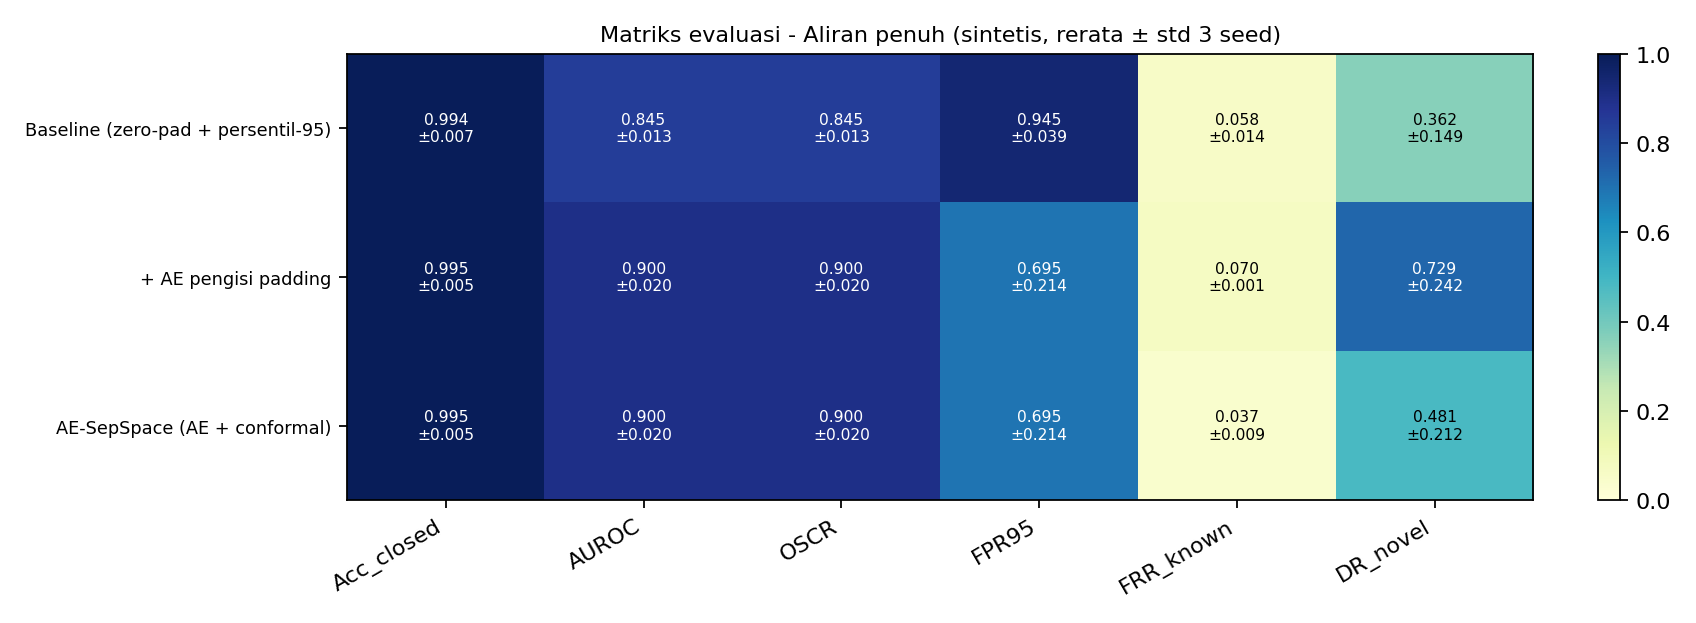

In [3]:
from IPython.display import Image, display
import os

file_path = "hasil_visualisasi/matriks_metrik_penuh.png"

if os.path.exists(file_path):
    display(Image(filename=file_path))
else:
    print(f"File {file_path} tidak ditemukan. Pastikan Anda telah menjalankan eksperimen terlebih dahulu.")

=== Confusion Matrix: Aliran Penuh ===


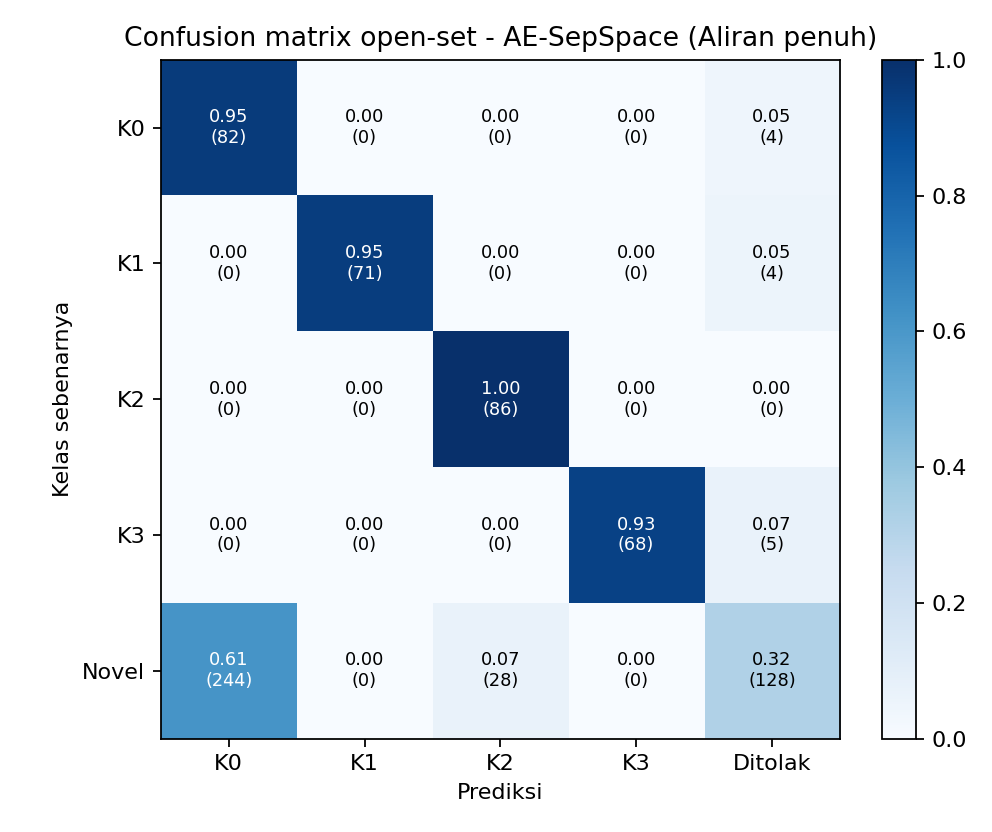


=== Confusion Matrix: Aliran Pendek (8 Paket Pertama) ===


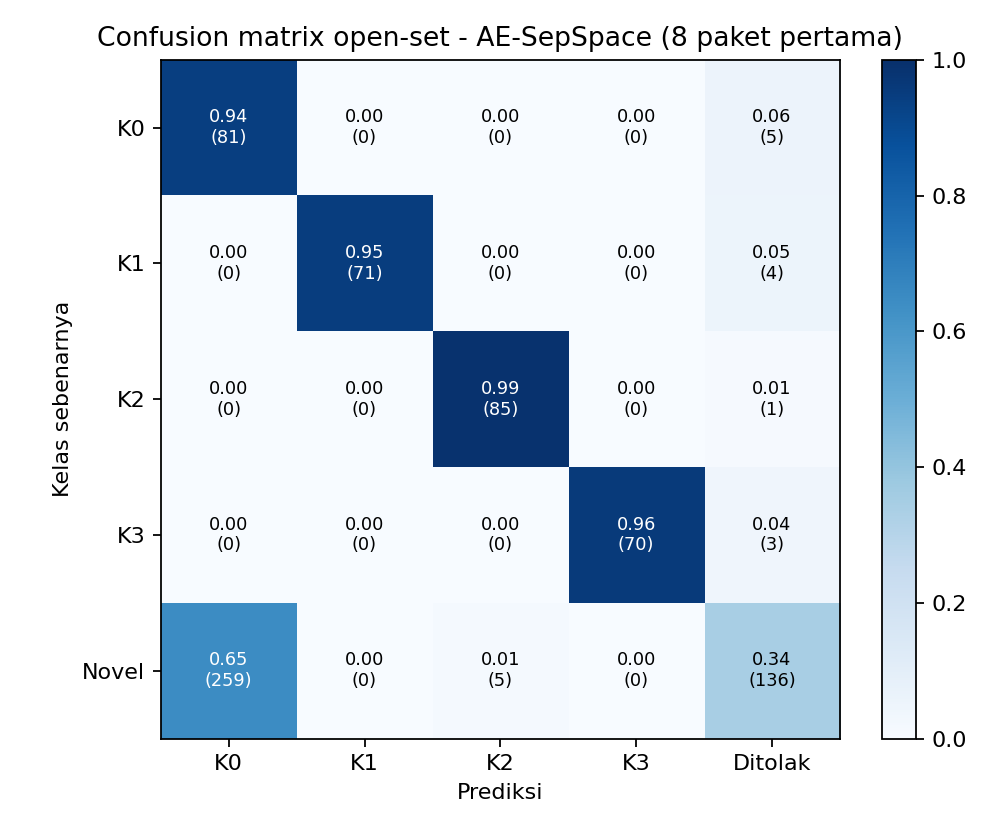

In [4]:
from IPython.display import Image, display
import os

confusion_penuh = "hasil_visualisasi/confusion_penuh.png"
confusion_pendek = "hasil_visualisasi/confusion_pendek.png"

if os.path.exists(confusion_penuh):
    print("=== Confusion Matrix: Aliran Penuh ===")
    display(Image(filename=confusion_penuh))
else:
    print("File confusion_penuh.png tidak ditemukan.")

if os.path.exists(confusion_pendek):
    print("\n=== Confusion Matrix: Aliran Pendek (8 Paket Pertama) ===")
    display(Image(filename=confusion_pendek))
else:
    print("File confusion_pendek.png tidak ditemukan.")

=== Kurva ROC: Aliran Penuh ===


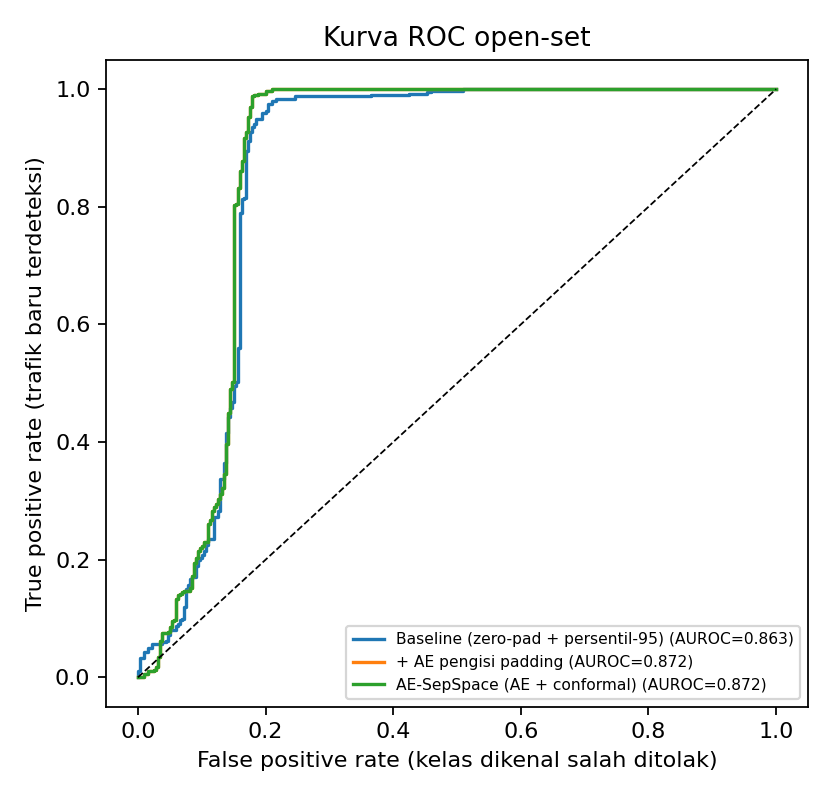


=== Kurva ROC: Aliran Pendek (8 Paket Pertama) ===


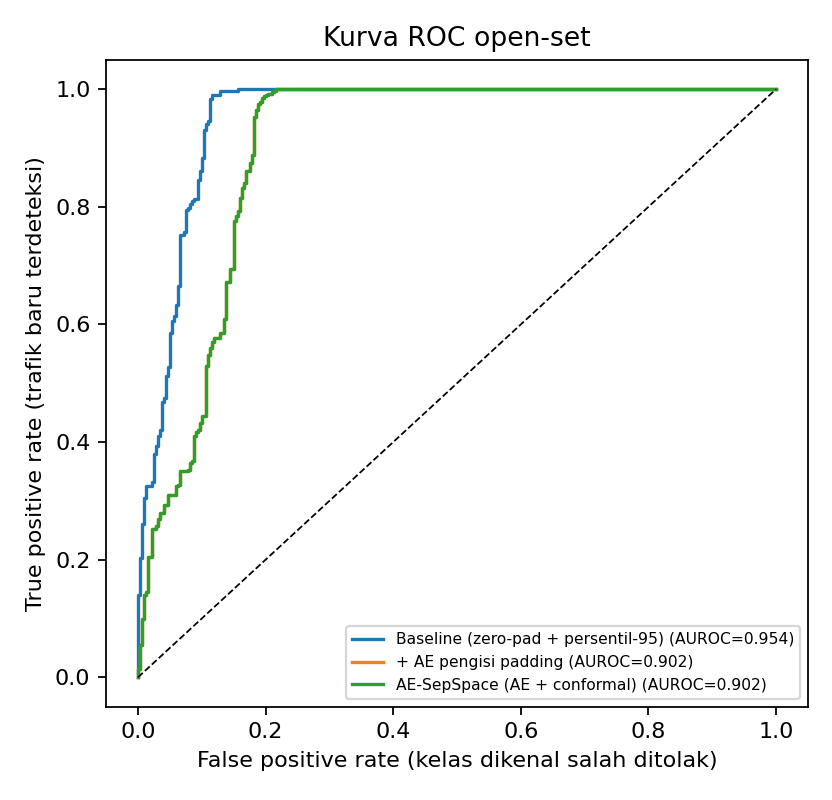

In [5]:
from IPython.display import Image, display
import os

roc_penuh = "hasil_visualisasi/roc_penuh.png"
roc_pendek = "hasil_visualisasi/roc_pendek.png"

if os.path.exists(roc_penuh):
    print("=== Kurva ROC: Aliran Penuh ===")
    display(Image(filename=roc_penuh))
else:
    print("File roc_penuh.png tidak ditemukan.")

if os.path.exists(roc_pendek):
    print("\n=== Kurva ROC: Aliran Pendek (8 Paket Pertama) ===")
    display(Image(filename=roc_pendek))
else:
    print("File roc_pendek.png tidak ditemukan.")

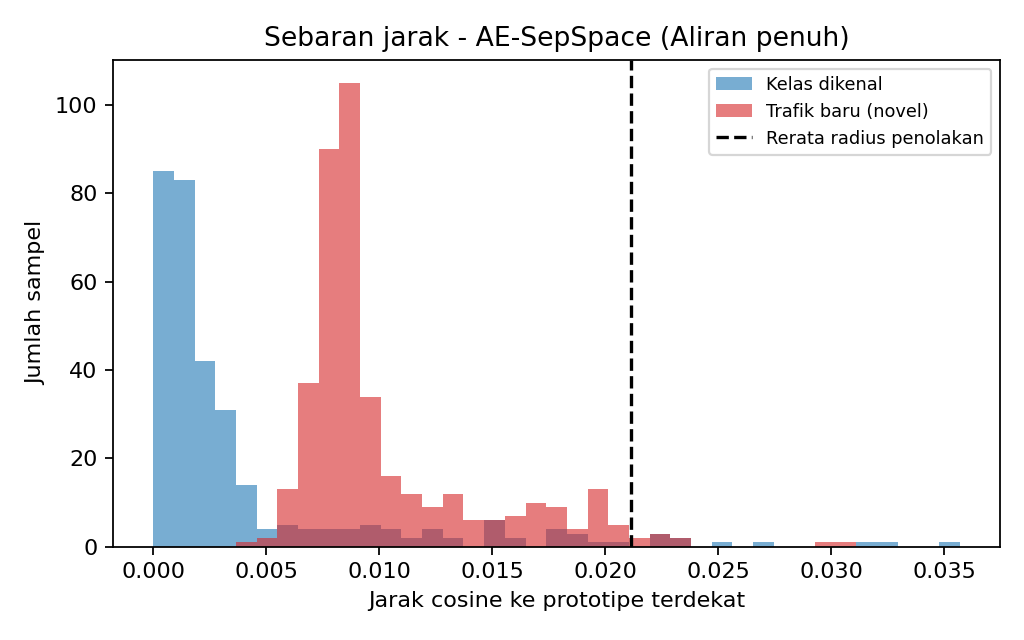

In [6]:
from IPython.display import Image, display
import os

file_path = "hasil_visualisasi/distribusi_jarak_penuh.png"

if os.path.exists(file_path):
    display(Image(filename=file_path))
else:
    print(f"File {file_path} tidak ditemukan. Pastikan Anda telah menjalankan eksperimen terlebih dahulu.")

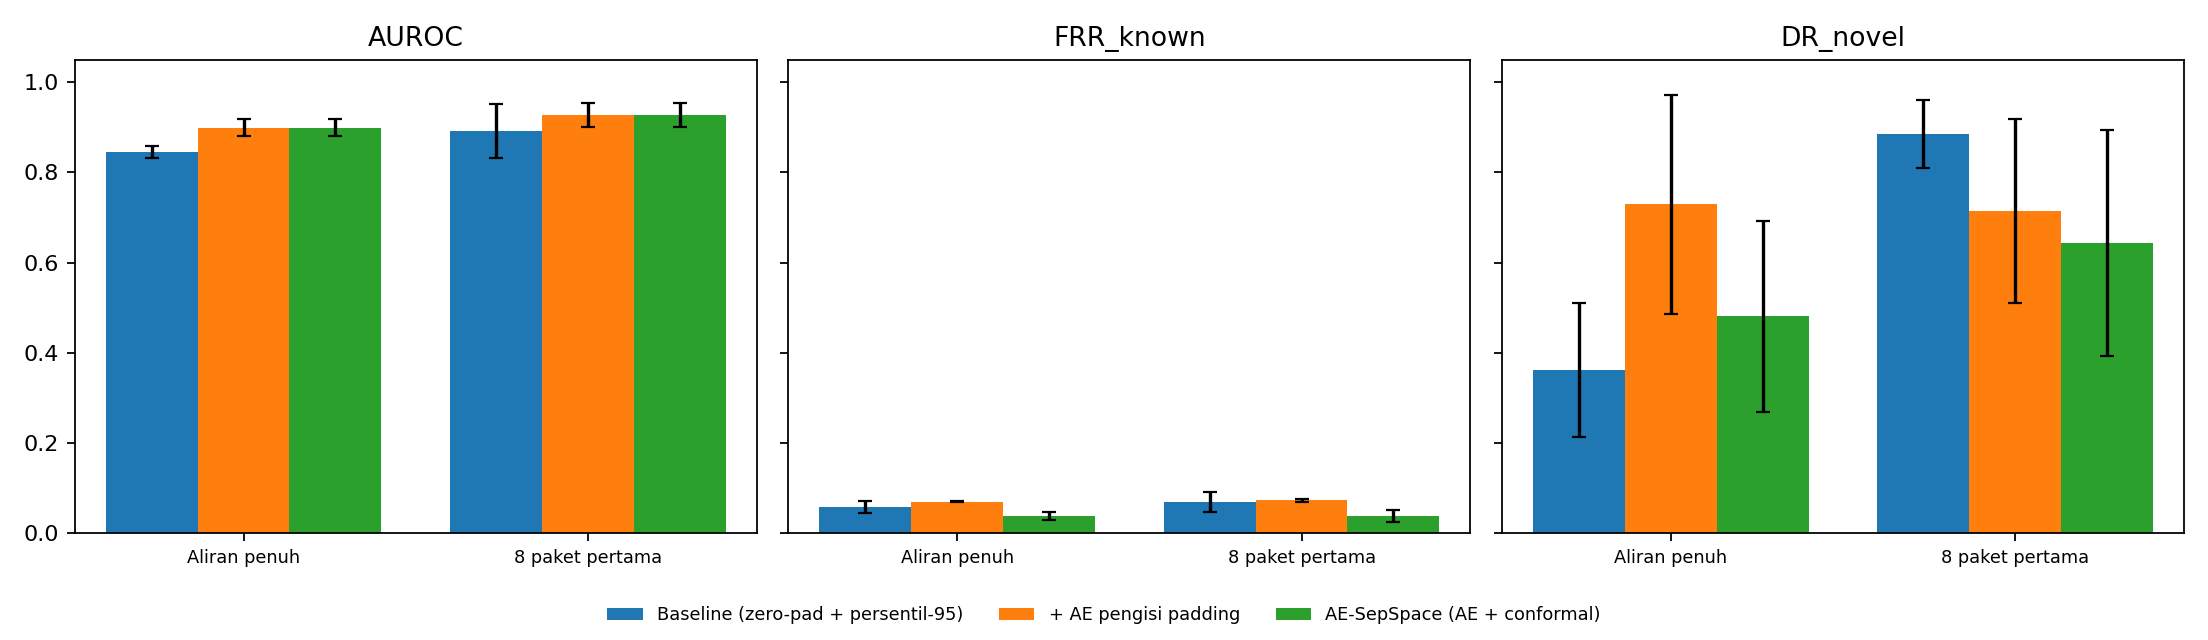

In [7]:
from IPython.display import Image, display
import os

file_path = "hasil_visualisasi/perbandingan_varian.png"

if os.path.exists(file_path):
    display(Image(filename=file_path))
else:
    print(f"File {file_path} tidak ditemukan. Pastikan eksperimen utama sudah selesai dijalankan.")